# K-Means

This first lesson of the unsupervised course starts with what changes when there is no target to predict. Then it builds K-Means, the most popular clustering algorithm, step by step: distances, the algorithm run by hand, and its main traps.

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import StandardScaler

# colour palette of the course
COLORS = ["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
pio.templates["course"] = go.layout.Template(layout_colorway=COLORS)
pio.templates.default = "plotly_white+course"

## Supervised vs unsupervised learning 🎯

In **supervised** learning, every observation comes with a target $Y$ (a price, a class...). The model learns to predict $Y$ from the features $X$, and we can check its answers against the true $Y$.

In **unsupervised** learning, **there is no target**. We only have $X$, and we look for a structure inside it: groups of similar observations (clustering, this section and the next one), a few variables that summarise many (PCA, section 3), or the topics of a set of texts (sections 4 and 5).

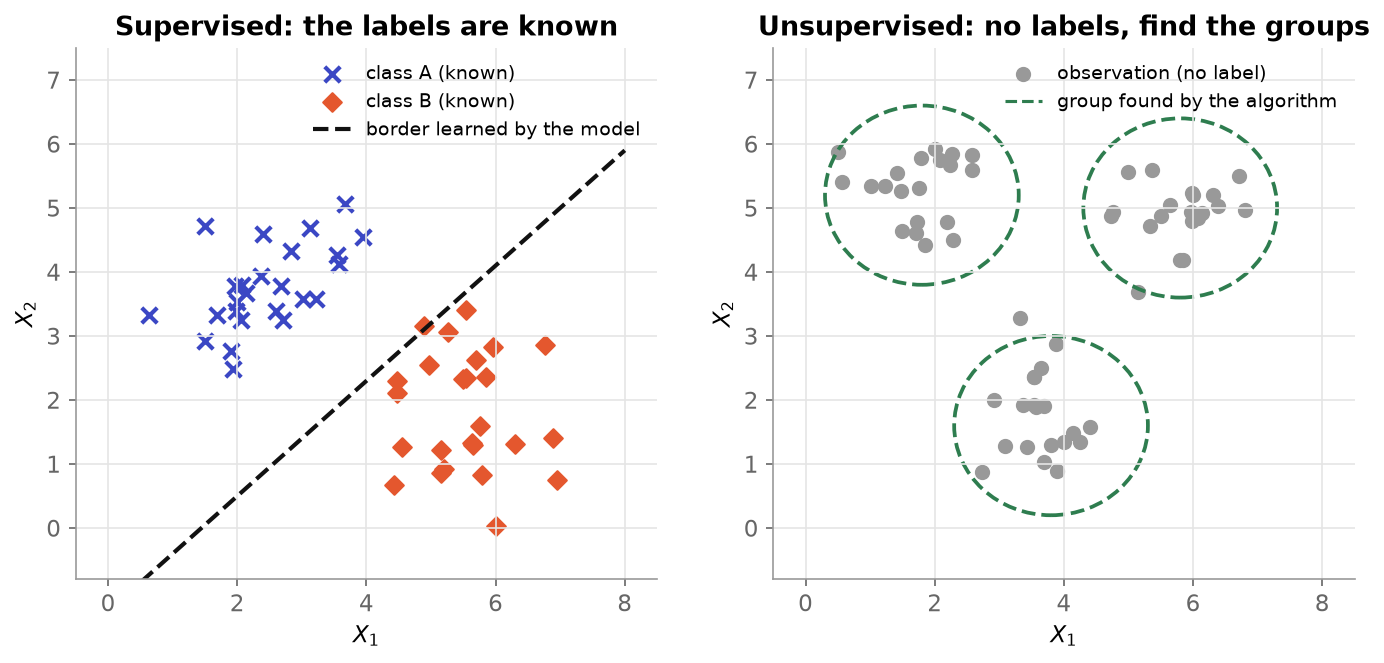

On the left, we know which points are crosses and which are diamonds: a model learns the border between them. On the right, nobody tells us anything, but three groups clearly appear.

The same difference, seen as datasets:

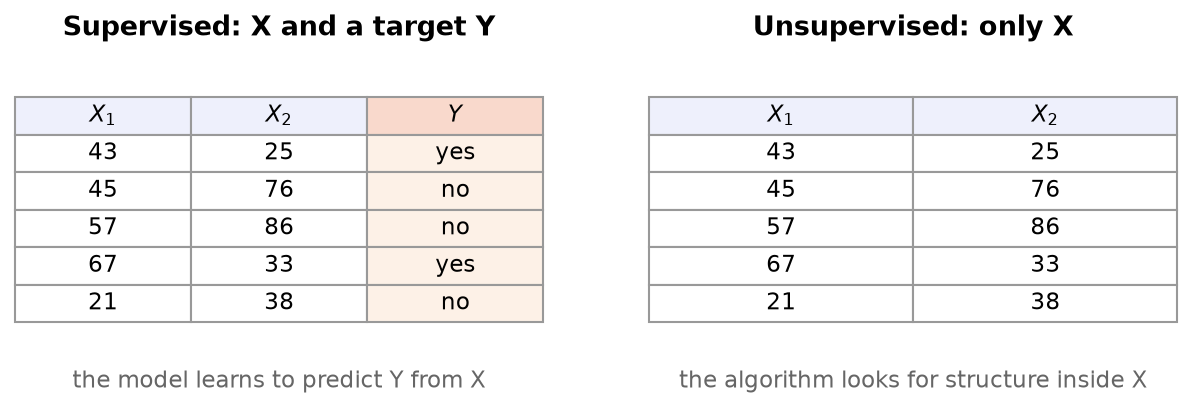

:::tip Intuition
Give a child a box of buttons and ask them to "sort them". Nobody gives the right answer: they may group them by colour, by size or by number of holes. Each choice is a different idea of what "similar" means. Clustering is the same: the algorithm builds the groups, but **you** choose how similarity is measured, and **you** must give a meaning to the groups at the end.
:::

### Use cases 🎭

Put yourself in the shoes of the marketing director of an online shop. The database describes each customer: the content of their baskets 🛒, how often they visit, what they look at... The director wants groups of customers who behave alike: students, parents, high spenders, careful buyers... But no column says "parent" or "student": there is no target to learn from.

👋 This is where **unsupervised machine learning** comes in. Typical examples of clustering:

* segmenting the customers of a shop by what they buy;
* grouping the users of a social network or a content platform by what they look at;
* in general, any situation where we want groups but have never **measured** a target variable.

## Clustering is built on distances 📏

Clustering makes groups so that observations of the **same** group are **close** to each other, and observations of **different** groups are **far** apart. "Close" and "far" need a **distance**: a way to turn two rows of the dataset into one number. The choice of the distance is crucial: change it, and the groups change.

For two observations $x$ and $y$ with $p$ numerical variables:

* **Euclidean distance** (L2), the distance "as the crow flies". It is the most used.
$$d_2(x,y)=\sqrt{\sum_{j=1}^{p}(x_j-y_j)^2}$$
* **Manhattan distance** (L1), the distance travelled along the streets of a city where you can only move along the axes. One big gap counts less than with L2 (it is not squared), so it is less sensitive to outliers.
$$d_1(x,y)=\sum_{j=1}^{p}|x_j-y_j|$$
* **Higher orders** (L$_q$), $d_q(x,y)=\left(\sum_{j}|x_j-y_j|^q\right)^{1/q}$. The higher $q$, the more the largest coordinate gap dominates. At the limit, $d_\infty(x,y)=\max_j|x_j-y_j|$.

![Left: between the points (1, 1) and (5, 4), the straight Euclidean segment has length 5 and the staircase Manhattan path has length 7. Right: the set of points at distance 1 from the centre is a diamond for L1, a circle for L2, a rounded square for L4 and a square for L-infinity](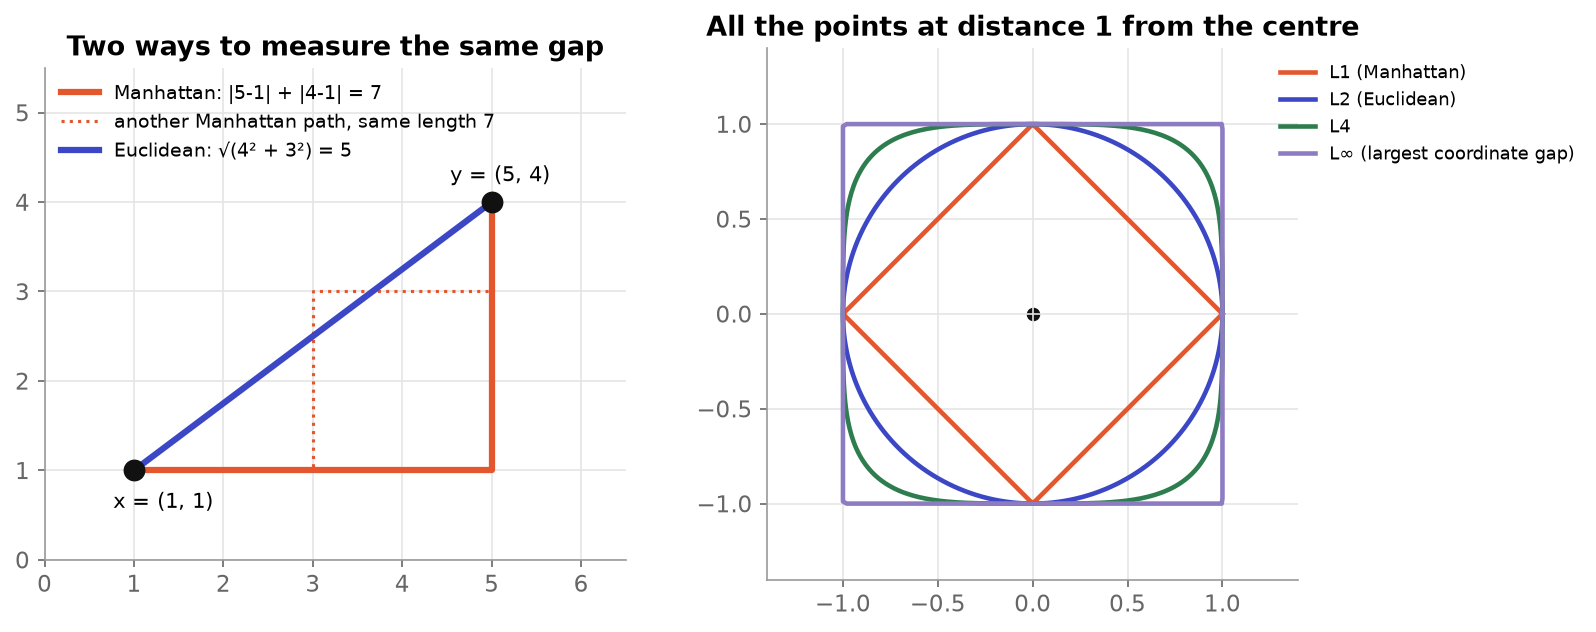)

On the right, each shape is a "circle" of radius 1 for one distance. They are different, so the same two points can be "close" for one distance and "far" for another.

#### See it with data 🔬: the distance decides who is the nearest neighbour

Three points: $a=(0,0)$, $b=(3,3)$ and $c=(5,0)$. Which one is closer to $a$, $b$ or $c$? We compute the distances by hand, then with scikit-learn's `pairwise_distances`.

In [ ]:
a, b, c = np.array([0, 0]), np.array([3, 3]), np.array([5, 0])
for name, d in [("euclidean", lambda u, v: np.sqrt(((u - v) ** 2).sum())),
                ("manhattan", lambda u, v: np.abs(u - v).sum()),
                ("chebyshev", lambda u, v: np.abs(u - v).max())]:       # chebyshev = L-infinity
    sk = pairwise_distances([a], [b, c], metric=name)[0]
    print(f"{name:<10} by hand: d(a,b) = {d(a, b):.2f}, d(a,c) = {d(a, c):.2f}   "
          f"scikit-learn: {sk.round(2)}   ->  nearest to a: {'b' if d(a, b) < d(a, c) else 'c'}")

euclidean  by hand: d(a,b) = 4.24, d(a,c) = 5.00   scikit-learn: [4.24 5.  ]   ->  nearest to a: b
manhattan  by hand: d(a,b) = 6.00, d(a,c) = 5.00   scikit-learn: [6. 5.]   ->  nearest to a: c
chebyshev  by hand: d(a,b) = 3.00, d(a,c) = 5.00   scikit-learn: [3. 5.]   ->  nearest to a: b


**What this shows:** with the Euclidean distance, $b$ is the nearest neighbour of $a$ (4.24 against 5.00). With the Manhattan distance, it is $c$ (6 against 5): $b$ differs from $a$ a little on **both** coordinates, $c$ a lot on **one** coordinate only, and L1 adds the gaps without squaring them. With L∞, only the largest gap counts and $b$ wins again (3 against 5). Scikit-learn gives the same numbers. Same data, different distance, different neighbour.

Distances also exist for data that is not numerical. For example, the **Levenshtein distance** between two words is the smallest number of letters to insert, delete or replace to go from one word to the other: "kitten" → "sitten" → "sittin" → "sitting" gives a distance of 3. Each type of data needs its own distance.

**K-Means works with the Euclidean distance** (squared, as we will see). It needs it because it represents each group by a **mean**, and the mean is exactly the point that minimises the sum of squared Euclidean distances. For other distances, other algorithms exist (K-Medoids, or DBSCAN in the next section).

## The K-Means algorithm ⚙️

K-Means separates the observations into $K$ groups (the **clusters**). Each cluster $C_k$ is represented by its **centre** $\mu_k$ (also called its **centroid**): the mean of its points. Each observation belongs to the cluster whose centre is the closest.

A good clustering has compact clusters: each point is close to its centre. K-Means measures this with the **inertia**, also called the within-cluster sum of squares (WCSS):

$$
I=\sum_{k=1}^{K}\;\sum_{x_i\in C_k}\left\|x_i-\mu_k\right\|^2
$$

the sum, over all points, of the squared Euclidean distance between the point and the centre of its cluster. K-Means looks for the clusters with the **smallest inertia**. Testing every possible partition is impossible (there are far too many), so it uses a simple loop:

0. **Choose** $K$, and place $K$ initial centres (for example, $K$ observations drawn at random).
1. **Assignment step:** each point joins the cluster of its **nearest** centre.
2. **Update step:** each centre moves to the **mean** of the points of its cluster.
3. **Repeat** steps 1 and 2 until no point changes cluster.

Each step can only lower the inertia: in step 1, each point picks the centre that makes its own term smallest; in step 2, the mean is the point that makes the sum of squared distances of the cluster smallest. The inertia goes down at every round and the number of possible partitions is finite, so the loop always stops. But it may stop in a **local** minimum, not the best possible clustering: we come back to this below.

:::tip Intuition
Three ice-cream sellers arrive on a beach, at random places. Each swimmer walks to the nearest seller (assignment). Each seller then moves to the middle of their own customers, to shorten their walk (update). Some swimmers now have a closer seller and change; the sellers move again... When nobody changes seller any more, the sellers have stopped moving: these are the final centres.
:::

### See it with data 🔬: K-Means by hand, step by step

14 points that form 3 groups. We place the 3 initial centres **on purpose** in a bad spot: on the first three points, all in the lower-left corner. First, the assignment step for one point, $P=(6.5, 2.8)$:

In [ ]:
points = np.array([[1, 1], [1.5, 2], [2, 1.2], [2.5, 2.3], [1.2, 3],      # lower-left
                   [6, 1.5], [7, 1], [7.5, 2.2], [6.5, 2.8],               # lower-right
                   [4, 6], [5, 7], [3.5, 7.5], [4.8, 5.8], [4.2, 8]])      # top
initial_centres = points[:3].copy()                                        # a bad start, on purpose

P = np.array([6.5, 2.8])
pd.DataFrame({"centre": [f"centre {k} = {tuple(initial_centres[k].tolist())}" for k in range(3)],
              "squared distance to P": ((initial_centres - P) ** 2).sum(axis=1)})

,centre,squared distance to P
0,"centre 0 = (1.0, 1.0)",33.49
1,"centre 1 = (1.5, 2.0)",25.64
2,"centre 2 = (2.0, 1.2)",22.81


$P$ is closest to centre 2 (squared distance 22.81, against 25.64 and 33.49): in step 1, it joins cluster 2. Now we code the whole loop and keep a record of every round.

In [ ]:
def assign(X, centres):
    sq_dist = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)    # one row per point, one column per centre
    labels = sq_dist.argmin(axis=1)                                       # step 1: nearest centre
    inertia = sq_dist[np.arange(len(X)), labels].sum()
    return labels, inertia

centres = initial_centres
history, previous = [], None
while True:
    labels, inertia = assign(points, centres)                                         # step 1
    new_centres = np.array([points[labels == k].mean(axis=0) for k in range(3)])      # step 2
    history.append({"labels": labels, "centres": centres, "new_centres": new_centres, "inertia": inertia})
    changed = len(points) if previous is None else int((labels != previous).sum())
    print(f"round {len(history)}: inertia = {inertia:6.2f}, points that changed cluster: {changed:>2}, "
          f"new centres: {new_centres.round(2).tolist()}")
    if previous is not None and changed == 0:                                         # 3. stop
        break
    centres, previous = new_centres, labels

round 1: inertia = 259.74, points that changed cluster: 14, new centres: [[1.0, 1.0], [3.34, 5.2], [5.8, 1.74]]
round 2: inertia =  40.55, points that changed cluster:  4, new centres: [[1.64, 1.9], [4.3, 6.86], [6.75, 1.88]]
round 3: inertia =  12.36, points that changed cluster:  0, new centres: [[1.64, 1.9], [4.3, 6.86], [6.75, 1.88]]


In [ ]:
fig = make_subplots(rows=1, cols=len(history), horizontal_spacing=0.04,
                    subplot_titles=[f"Round {r + 1}: inertia {h['inertia']:.1f}" for r, h in enumerate(history)])
for r, h in enumerate(history):
    for k in range(3):
        part = points[h["labels"] == k]
        fig.add_trace(go.Scatter(x=part[:, 0], y=part[:, 1], mode="markers", name=f"cluster {k}",
                                 marker=dict(color=COLORS[k], size=10), legendgroup=str(k), showlegend=(r == 0)),
                      row=1, col=r + 1)
        old, new = h["centres"][k], h["new_centres"][k]
        fig.add_trace(go.Scatter(x=[old[0]], y=[old[1]], mode="markers", name="centre used for step 1",
                                 marker=dict(symbol="x", size=16, color=COLORS[k], line=dict(width=2, color="#111111")),
                                 legendgroup="c", showlegend=(r == 0 and k == 0)), row=1, col=r + 1)
        fig.add_annotation(x=new[0], y=new[1], ax=old[0], ay=old[1], xref=f"x{r + 1}", yref=f"y{r + 1}",
                           axref=f"x{r + 1}", ayref=f"y{r + 1}", showarrow=True, arrowhead=2, arrowwidth=2,
                           arrowcolor=COLORS[k])
fig.update_xaxes(range=[0, 8.5])
fig.update_yaxes(range=[0, 8.8])
fig.update_layout(height=420, title="Assignment (colours) with the current centres (×), then update (arrows: the centres move to the mean)")
fig.show()

**What this shows:**

* **Round 1:** the 3 centres are all in the lower-left corner. Centre 0 gets only the point it sits on; centres 1 and 2 share the 13 other points. The inertia is huge (259.7). Then the update step pulls centres 1 and 2 far away, to the middle of their points (long arrows).
* **Round 2:** with the new centres, the lower-left group goes to cluster 0, the lower-right one to cluster 2 and the top one to cluster 1. 4 points changed cluster and the inertia drops to 40.6. The centres move again, to the middle of their groups.
* **Round 3:** no point changes cluster, so the centres do not move any more (the arrows have length zero): the algorithm stops, with an inertia of 12.4.

Let's ask scikit-learn to do the same, starting from the same 3 initial centres (`init=initial_centres`, `n_init=1`):

In [ ]:
km = KMeans(n_clusters=3, init=initial_centres, n_init=1).fit(points)
print("our centres:         ", history[-1]["new_centres"].round(2).tolist())
print("scikit-learn centres:", km.cluster_centers_.round(2).tolist())
print("same labels:", (km.labels_ == history[-1]["labels"]).all())
print(f"our inertia: {history[-1]['inertia']:.2f}   scikit-learn inertia_: {km.inertia_:.2f}")

our centres:          [[1.64, 1.9], [4.3, 6.86], [6.75, 1.88]]
scikit-learn centres: [[1.64, 1.9], [4.3, 6.86], [6.75, 1.88]]
same labels: True
our inertia: 12.36   scikit-learn inertia_: 12.36


**What this shows:** scikit-learn finds exactly the same 3 centres, the same cluster for each point and the same inertia (12.36). `KMeans` runs the loop we have just written, only faster. After `fit`, `cluster_centers_` holds the centres, `labels_` the cluster of each point and `inertia_` the final inertia. `predict` assigns **new** points to the nearest centre: this is step 1, applied once.

## Sensitivity to the initial centres 🎲

The final clusters depend on the initial centres. A bad start can trap the algorithm in a **local minimum**: no single point wants to change cluster, yet a better clustering exists.

#### See it with data 🔬: same data, two different starts

300 points in 6 groups. We run K-Means 50 times with the most naive start, `init="random"` (6 observations drawn at random) and a single run each time (`n_init=1`), only changing the random seed. We draw the best and the worst result.

In [ ]:
X_blobs, _ = make_blobs(n_samples=300, centers=6, cluster_std=0.7, random_state=2)
runs = [KMeans(n_clusters=6, init="random", n_init=1, random_state=seed).fit(X_blobs) for seed in range(50)]
inertias = np.array([r.inertia_ for r in runs])
best, worst = runs[inertias.argmin()], runs[inertias.argmax()]

fig = make_subplots(rows=1, cols=2, subplot_titles=[f"Best run: inertia {best.inertia_:.0f}",
                                                    f"Worst run: inertia {worst.inertia_:.0f}"])
for col, run in [(1, best), (2, worst)]:
    fig.add_trace(go.Scatter(x=X_blobs[:, 0], y=X_blobs[:, 1], mode="markers", showlegend=False,
                             marker=dict(color=[COLORS[l] for l in run.labels_], size=6)), row=1, col=col)
    fig.add_trace(go.Scatter(x=run.cluster_centers_[:, 0], y=run.cluster_centers_[:, 1], mode="markers",
                             showlegend=False, marker=dict(symbol="x", size=14, color="#111111")), row=1, col=col)
fig.update_layout(height=420, title="K-Means with init='random' and n_init=1: the start matters")
fig.show()

**What this shows:** on the left, each of the 6 groups gets its own centre (inertia 284). On the right, two groups have to share one centre while another group is cut in two by two centres: the inertia is much higher, but no point can improve things by changing cluster on its own, so the loop has stopped. Same data, same algorithm: only the starting centres were different.

Two tools fix this, and scikit-learn uses both:

* **k-means++** (`init="k-means++"`, the default): smarter initial centres. The first one is an observation drawn at random. Each next one is drawn with a probability proportional to the **squared distance to the nearest centre already chosen**: far-away points are much more likely to be picked. The initial centres are spread out, so they rarely start two in the same group.
* **`n_init`**: run the whole algorithm several times, from different starts, and **keep the run with the lowest inertia**. Careful: with `init="k-means++"`, scikit-learn's default `n_init="auto"` does **one** single run. Ask for several, for example `n_init=10`.

#### See it with data 🔬: how often does K-Means get trapped?

Same data. For each strategy, 50 runs with 50 different seeds. We call a run "trapped" when its inertia is more than 10% above the best inertia ever found.

In [ ]:
best_inertia = inertias.min()
rows = []
for init in ["random", "k-means++"]:
    for n_init in [1, 10]:
        scores = np.array([KMeans(n_clusters=6, init=init, n_init=n_init, random_state=seed).fit(X_blobs).inertia_
                           for seed in range(50)])
        best_inertia = min(best_inertia, scores.min())
        rows.append({"init": init, "n_init": n_init, "scores": scores})
pd.DataFrame([{"init": r["init"], "n_init": r["n_init"],
               "trapped runs (out of 50)": int((r["scores"] > 1.1 * best_inertia).sum()),
               "worst inertia": round(r["scores"].max())} for r in rows])

,init,n_init,trapped runs (out of 50),worst inertia
0,random,1,31,560
1,random,10,0,285
2,k-means++,1,5,445
3,k-means++,10,0,284


**What this shows:** with random starts and a single run, 31 runs out of 50 get trapped. k-means++ alone brings this down to 5, and 10 runs per fit (`n_init=10`) remove the problem with both initialisations here. In practice: keep `init="k-means++"` and ask for `n_init=10`, as we will do in the rest of the course. Even so, K-Means gives no guarantee to find the best clustering, so never trust a single run blindly.

## Scale the variables first ⚖️

K-Means compares points with the Euclidean distance, which adds up the gaps of all the variables. A variable measured in large numbers (an income in euros) dwarfs a variable measured in small numbers (an age in years), and the clusters only follow the large one.

#### See it with data 🔬: clustering customers with and without scaling

200 simulated customers: young (around 25) and senior (around 60), with incomes spread between 20,000 € and 80,000 € in both groups. The two real groups differ by age only. We ask K-Means for 2 clusters, before and after standardisation (`StandardScaler`: each variable gets mean 0 and standard deviation 1).

In [ ]:
rng = np.random.default_rng(0)
customers = pd.DataFrame({
    "age": np.r_[rng.normal(25, 4, 100), rng.normal(60, 4, 100)],
    "income": rng.uniform(20_000, 80_000, 200),
})
raw_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(customers)
scaled_labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(customers))
print("standard deviations before scaling:", customers.std().round(0).to_dict())

fig = make_subplots(rows=1, cols=2, subplot_titles=["Raw variables", "Standardised variables"])
for col, labels in [(1, raw_labels), (2, scaled_labels)]:
    fig.add_trace(go.Scatter(x=customers.age, y=customers.income, mode="markers", showlegend=False,
                             marker=dict(color=[COLORS[l] for l in labels], size=6)), row=1, col=col)
    print(f"{'raw' if col == 1 else 'scaled':>6}: mean age of each cluster = "
          f"{customers.groupby(labels).age.mean().round(1).tolist()}")
fig.update_xaxes(title_text="age")
fig.update_yaxes(title_text="income (€)", col=1)
fig.update_layout(height=400, title="Same data, same K-Means: only the scale of the variables changes")
fig.show()

standard deviations before scaling: {'age': 18.0, 'income': 17464.0}
   raw: mean age of each cluster = [42.6, 42.5]
scaled: mean age of each cluster = [59.8, 25.3]


**What this shows:** the income varies by about 17,000 €, the age by about 18 years. On the raw data, a gap of 1 € weighs as much as a gap of 1 year, so the age is invisible: K-Means cuts the customers into low and high incomes, and both clusters have a mean age around 42.5. After standardisation, both variables count equally and K-Means finds the two real groups (mean ages 25.3 and 59.8). **Always scale your variables before K-Means** (unless they already share the same unit and you want the large ones to count more).

## The limits of K-Means 🚧

Each point goes to its **nearest** centre. So the border between two clusters is always a straight line, halfway between their centres. This builds clusters that are **convex** (no holes, no bananas), roughly **round**, and of similar **width**. When the real groups do not look like this, K-Means fails, however well it is initialised.

#### See it with data 🔬: two shapes that K-Means cannot find

On the left, two interleaved half-moons. On the right, one large, spread-out group next to two small, dense ones. In both cases, we know the true groups and ask K-Means for the right number of clusters.

In [ ]:
X_moons, y_moons = make_moons(n_samples=300, noise=0.06, random_state=0)
X_sizes, y_sizes = make_blobs(n_samples=[400, 60, 60], centers=[[0, 0], [4.5, 2.5], [4.5, -2.5]],
                              cluster_std=[1.6, 0.35, 0.35], random_state=0)

fig = make_subplots(rows=2, cols=2, vertical_spacing=0.12,
                    subplot_titles=["Half-moons: true groups", "Different sizes and densities: true groups",
                                    "Half-moons: K-Means, K=2", "Different sizes and densities: K-Means, K=3"])
for col, (X, y, k) in enumerate([(X_moons, y_moons, 2), (X_sizes, y_sizes, 3)], start=1):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    # cluster numbers are arbitrary: give each cluster the colour of the true group it overlaps most
    match = {c: np.bincount(y[km.labels_ == c]).argmax() for c in range(k)}
    for row, labels in [(1, y), (2, np.array([match[c] for c in km.labels_]))]:
        fig.add_trace(go.Scatter(x=X[:, 0], y=X[:, 1], mode="markers", showlegend=False,
                                 marker=dict(color=[COLORS[l] for l in labels], size=5)), row=row, col=col)
    fig.add_trace(go.Scatter(x=km.cluster_centers_[:, 0], y=km.cluster_centers_[:, 1], mode="markers", showlegend=False,
                             marker=dict(symbol="x", size=14, color="#111111")), row=2, col=col)
fig.update_layout(height=700, title="K-Means draws straight borders halfway between the centres")
fig.show()

big = km.labels_[y_sizes == 0]                       # clusters given to the 400 points of the large group
print(f"points of the large group outside its main cluster: {(big != np.bincount(big).argmax()).sum()} out of 400")

points of the large group outside its main cluster: 63 out of 400


**What this shows:** on the half-moons, K-Means cuts the plane with a straight line: each cluster mixes a piece of each moon. On the right, the border between two clusters sits halfway between their centres. The large group spreads beyond that halfway line, so its edge goes to the small clusters: 63 of its 400 points end up in the cluster of a small group. K-Means has no idea that a group can be wider or denser than another.

The next section presents **DBSCAN**, which builds clusters from dense regions and handles both cases.

Other limits to keep in mind:

* $K$ must be chosen in advance. The next lesson shows how to choose it.
* The centres are means: they are not real observations, and an outlier pulls the mean of its cluster towards it.
* With many variables, the distances between points grow and become similar, and there are many centre coordinates to read: the clusters are harder to build **and** to interpret.

### Summary ✅

| Advantages | Limits |
|---|---|
| Simple: easy to understand and to explain. | $K$ must be chosen in advance. |
| Fast: works on large datasets. | The result depends on the initial centres (use k-means++ and `n_init`). |
| Each cluster has a centre that summarises it. | Needs scaled, numerical variables (Euclidean distance). |
| Assigns new observations easily (`predict`). | Only finds round, convex clusters of similar width. |
| | The centres are not real observations; outliers pull them. |

## Resources 📚

* [Clustering with K-Means, scikit-learn user guide](https://scikit-learn.org/stable/modules/clustering.html#k-means)
* [In depth: K-Means clustering, *Python Data Science Handbook*, J. VanderPlas](https://jakevdp.github.io/PythonDataScienceHandbook/05.11-k-means.html)
* [The k-means++ paper: D. Arthur and S. Vassilvitskii, 2007](https://theory.stanford.edu/~sergei/papers/kMeansPP-soda.pdf)